# 🎓 第2章 第1课：投资组合排序法 —— 分班考试

**本节目标**：用“分班考试”的比喻，跑通排序法的完整流程。

对应原书 2.1 节。我们会做三件事：

1. **单变量排序**：按 BM（账面市值比）分 10 组，看组均收益是否单调；
2. **价差组合**：高组 − 低组 = 价值因子收益率，用 Newey-West t 检验看显著性；
3. **双重排序**：控制市值后，BM 还有没有增量解释力。

> ⚠️ 数据说明：日线价格是真实 A 股快照；估值只有一期快照，notebook 用价格路径推导了一个**教学用月度估值面板**。收益大小仅用于演示方法，不代表真实 A 股结论。

In [1]:
import sys
from pathlib import Path

def _find_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / 'src' / 'factor_zero').exists():
            return p
    raise FileNotFoundError('找不到仓库根目录，请从仓库内启动 notebook')
ROOT = _find_root()
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from factor_zero.sorting import quantile_group, sort_portfolios, spread_return, monotonicity_test
from factor_zero.factors import monthly_returns, momentum, book_to_market, log_market_cap
from factor_zero.statistics import nw_t_stat

def _find_sample():
    for p in [ROOT / 'data' / 'sample', Path('data/sample'), Path.cwd().parents[2] / 'data' / 'sample']:
        if p.exists():
            return p
    raise FileNotFoundError('找不到 data/sample，请从仓库内启动 notebook')
SAMPLE = _find_sample()
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC', 'DejaVu Sans']
print('✅ 环境就绪，开始学习！')

✅ 环境就绪，开始学习！


## 0) 加载数据：把日线变成月度面板

`load_ashare_snapshot()` 做四件事：

- 读取 87 只股票的日线收盘价；
- 月末重采样 → 月度收益率（丢掉有缺失的股票，保留 81 只完整样本）；
- 用估值快照 + 价格路径推导教学用月度 PB / 总市值；
- 构造 BM、对数市值、12-1 动量三个因子面板。

In [2]:
def load_ashare_snapshot():
    """加载 87 只 A 股快照，构造教学用月度面板。

    真实数据：日线收盘价（2018-2024）+ 估值快照（2026-09-01）。
    估值快照只有一期；为了演示“逐期排序”，这里用价格路径 + 快照估值
    推导一个教学用月度基本面面板（合成，仅用于方法演示，不代表真实历史估值）。
    """
    daily_dir = SAMPLE / 'a_share_snapshot' / 'daily'
    codes = sorted(p.stem for p in daily_dir.glob('*.csv'))
    prices = {}
    for code in codes:
        df = pd.read_csv(daily_dir / f'{code}.csv', parse_dates=['date'])
        prices[code] = df.set_index('date')['close']
    price_df = pd.DataFrame(prices).sort_index()

    ret = monthly_returns(price_df).dropna(axis=1, how='any')
    fund = pd.read_csv(SAMPLE / 'a_share_snapshot' / 'fundamentals.csv', parse_dates=['trade_date'])
    fund['stock'] = fund['stock'].astype(int).astype(str).str.zfill(6)
    fund = fund.set_index('stock').reindex(ret.columns)

    month_end = price_df.resample('ME').last().ffill().reindex(columns=ret.columns)
    last_price = month_end.iloc[-1]
    shares = fund['total_mv'] / last_price
    total_mv = month_end.mul(shares, axis=1)

    base_pb = fund['pb']
    months = np.arange(len(month_end))
    phase = pd.Series(np.linspace(0, 2 * np.pi, len(ret.columns), endpoint=False), index=ret.columns)
    seasonal = pd.DataFrame(
        np.sin(months[:, None] / 12 * 2 * np.pi + phase.values[None, :]),
        index=month_end.index, columns=ret.columns,
    )
    pb = (1 + 0.15 * seasonal).mul(base_pb, axis=1).clip(lower=0.05)
    pe = pb / 0.10  # 教学用固定 ROE=10%，仅用于补全字段

    panel = pd.concat([
        pd.DataFrame({
            'stock': col, 'trade_date': month_end.index,
            'pb': pb[col].values, 'pe': pe[col].values, 'total_mv': total_mv[col].values,
        }) for col in ret.columns
    ], ignore_index=True)

    bm = book_to_market(panel).reindex(index=ret.index, columns=ret.columns)
    mv = log_market_cap(panel).reindex(index=ret.index, columns=ret.columns)
    mom = momentum(ret, lookback=12, skip=1).reindex(index=ret.index, columns=ret.columns)
    return {'ret': ret, 'bm': bm, 'mv': mv, 'mom': mom, 'price': price_df, 'panel': panel}

data = load_ashare_snapshot()
print('月收益:', data['ret'].shape)
print('BM:', data['bm'].shape, '| 对数市值:', data['mv'].shape, '| 动量:', data['mom'].shape)
data['ret'].tail(2).round(4)

月收益: (83, 81)
BM: (83, 81) | 对数市值: (83, 81) | 动量: (83, 81)


,000001,000002,000063,000100,000333,000338,000568,000625,000651,000725,...,601636,601668,601688,601728,601857,601888,601899,601989,601995,603501
date,,,,,,,,,,,,,,,,,,,,,
2024-11-30,0.0000,-0.0733,0.0293,-0.1167,-0.0180,0.0056,0.0238,0.0409,-0.0327,-0.0788,...,-0.1422,-0.0074,0.019,-0.0351,-0.0067,0.0254,-0.0662,-0.0343,0.0620,-0.0806
2024-12-31,0.0287,-0.1558,0.2964,0.0749,0.0726,0.0205,-0.0975,-0.0325,0.0803,0.0214,...,-0.0728,0.0037,-0.021,0.0581,0.1120,-0.0364,-0.0375,0.0021,-0.1384,0.0606


## 1) 单变量排序：按 BM 分 10 组

**排序法只假设“变量高低 ≈ 因子暴露高低”**，不假设任何数学关系（2.1.2 节）。

做法：用 **t 月末的 BM** 分组，看 **t+1 月** 的组合收益——避免未来函数。

In [3]:
ret, bm = data['ret'], data['bm']
common_idx = ret.index.intersection(bm.index)
group_dict, port_dates = {}, []
for t in range(len(common_idx) - 1):
    d, d_next = common_idx[t], common_idx[t + 1]
    g = quantile_group(bm.loc[d].dropna(), n_groups=10)
    group_dict[d_next] = g
    port_dates.append(d_next)
groups = pd.DataFrame(group_dict).T.reindex(index=ret.index)
port = sort_portfolios(ret, groups, n_groups=10)
print('组合收益矩阵:', port.shape)
port.tail(3).round(4)

组合收益矩阵: (83, 10)


,1,2,3,4,5,6,7,8,9,10
date,,,,,,,,,,
2024-10-31,-0.0467,-0.0572,-0.0294,-0.0506,-0.0337,0.0066,0.0239,-0.0014,-0.0657,-0.0379
2024-11-30,0.0110,0.0154,0.0031,0.0034,-0.0115,-0.0291,0.0055,-0.0488,0.0402,0.0178
2024-12-31,-0.0003,-0.0398,-0.0351,-0.0159,0.0385,-0.0434,-0.0138,0.0280,0.0105,0.0139


Spearman 秩相关: -0.842  （≈1 单调上升；≈-1 单调下降；接近 0 无明显单调）


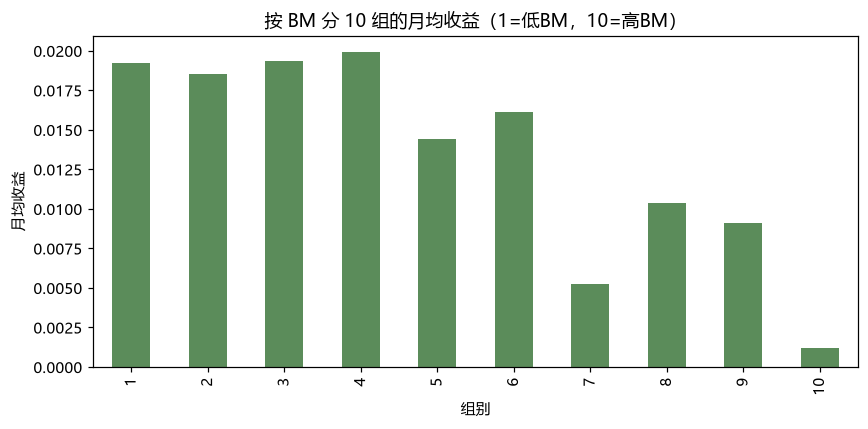

1     0.0192
2     0.0185
3     0.0193
4     0.0199
5     0.0144
6     0.0161
7     0.0053
8     0.0104
9     0.0091
10    0.0012
dtype: float64

In [4]:
means = port.mean()
res = monotonicity_test(port)
print(f'Spearman 秩相关: {res["rho"]:.3f}  （≈1 单调上升；≈-1 单调下降；接近 0 无明显单调）')

fig, ax = plt.subplots(figsize=(8, 4))
means.plot(kind='bar', ax=ax, color='#5B8C5A')
ax.set_title('按 BM 分 10 组的月均收益（1=低BM，10=高BM）')
ax.set_xlabel('组别'); ax.set_ylabel('月均收益')
plt.tight_layout(); plt.show()
means.round(4)

> 🔍 **先别失望**：本例的估值面板是教学合成数据，没有刻意制造“价值溢价”，所以 rank 相关可能为负、价差可能不显著。这正好说明：排序法是一把尺子，结果要由数据说话，不能预设结论。


### 价差组合：高 BM − 低 BM

价差组合（做多高组、做空低组）的收益率，就是**价值因子的收益率**。
用 Newey-West 调整后的 t 值判断：这是“真实力”还是“运气”。

In [5]:
spread = spread_return(port, high=10, low=1).dropna()
t_val, se = nw_t_stat(spread)
print(f'价差组合月均收益: {spread.mean()*100:.3f}%')
print(f'Newey-West 调整后 t = {t_val:.2f}')
print('|t| > 2 → 在 95% 置信下显著' if abs(t_val) > 2 else '|t| ≤ 2 → 不显著，不能排除运气')

价差组合月均收益: -1.800%
Newey-West 调整后 t = -2.28
|t| > 2 → 在 95% 置信下显著


## 2) 双重排序：控制市值

高 BM 组会不会恰好全是小盘股？用**条件双重排序**：

1. 先按市值分 5 层；
2. 每层内部再按 BM 分 5 组；
3. 在每一层内算 BM 价差（组5 − 组1），再看各层结果。

这样市值被“控制住”了，BM 的效果更干净。

In [6]:
mv, bm, ret = data['mv'], data['bm'], data['ret']
common = ret.index.intersection(bm.index).intersection(mv.index)
spreads_by_size = {}
for t in range(len(common) - 1):
    d, dn = common[t], common[t + 1]
    size_g = quantile_group(mv.loc[d].dropna(), n_groups=5)
    for s in range(1, 6):
        inside = size_g[size_g == s].index
        if len(inside) < 5:
            continue
        bm_inside = bm.loc[d, inside].dropna()
        g = quantile_group(bm_inside, n_groups=5)
        sub_ret = ret.loc[dn, g.index]
        sub_ret_df = sub_ret.to_frame().T.copy(); sub_ret_df.index = [dn]
        g_df = g.to_frame().T.copy(); g_df.index = [dn]
        port_s = sort_portfolios(sub_ret_df, g_df, n_groups=5)
        spreads_by_size.setdefault(s, []).append(port_s.iloc[0, 4] - port_s.iloc[0, 0])

print('市值层内 BM 价差月均收益（每层 = 控制市值后的 BM 效果）:')
all_spreads = []
for s in sorted(spreads_by_size):
    vals = pd.Series(spreads_by_size[s])
    all_spreads.extend(vals.tolist())
    print(f'  市值第{s}层: {vals.mean()*100:+.3f}%/月 (共{len(vals)}期)')
print(f'  五层平均: {pd.Series(all_spreads).mean()*100:+.3f}%/月')

市值层内 BM 价差月均收益（每层 = 控制市值后的 BM 效果）:
  市值第1层: -1.139%/月 (共82期)
  市值第2层: -2.223%/月 (共82期)
  市值第3层: -1.766%/月 (共82期)
  市值第4层: -0.698%/月 (共82期)
  市值第5层: -0.570%/月 (共82期)
  五层平均: -1.279%/月


## ✋ 试一试

1. 把单变量排序改成按**动量**排序（`data['mom']`），价差组合还显著吗？
2. 把 `n_groups=10` 改成 5，单调性和价差会怎么变？
3. 双重排序里把“先市值、后 BM”改成“先 BM、后市值”，结果有什么不同？

## ✅ 本节小结

- 排序法绕开了“暴露未知”的循环：**变量高低 ≈ 暴露高低**；
- 价差组合 = 因子收益率；NW t 检验判断显著性；
- 双重排序控制其他因子（这里是市值），看**增量解释力**；
- 示例数据为教学面板，收益大小不代表真实 A 股结论。

> 下一课：三种回归方法——时序、截面、Fama-MacBeth，用已知真相的数据验证。